In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt
import os

print("MNE versão:", mne.__version__)

Matplotlib is building the font cache; this may take a moment.


MNE versão: 1.12.1


In [2]:
caminho_arquivo = "chb01/chb01_03.edf"

# Carrega o arquivo EDF usando MNE
# preload=True: carrega os dados na memória imediatamente (necessário para manipular)
dados_brutos = mne.io.read_raw_edf(caminho_arquivo, preload=True, verbose=False)

print(dados_brutos)
print("\nInformações do arquivo:")
print(dados_brutos.info)

<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>

Informações do arquivo:
<Info | 8 non-empty values
 bads: []
 ch_names: FP1-F7, F7-T7, T7-P7, P7-O1, FP1-F3, F3-C3, C3-P3, P3-O1, ...
 chs: 23 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: 2076-11-06 13:43:04 UTC
 nchan: 23
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: Surrogate>
>


In [3]:
caminho_arquivo = "chb01/chb01_03.edf"

# Carrega o arquivo EDF usando MNE
# preload=True: carrega os dados na memória imediatamente (necessário para manipular)
dados_brutos = mne.io.read_raw_edf(caminho_arquivo, preload=True, verbose=False)

print(dados_brutos)
print("\nInformações do arquivo:")
print(dados_brutos.info)

<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>

Informações do arquivo:
<Info | 8 non-empty values
 bads: []
 ch_names: FP1-F7, F7-T7, T7-P7, P7-O1, FP1-F3, F3-C3, C3-P3, P3-O1, ...
 chs: 23 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: 2076-11-06 13:43:04 UTC
 nchan: 23
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: Surrogate>
>


In [4]:
print("Canais disponíveis:")
for i, nome_canal in enumerate(dados_brutos.ch_names):
    print(f"  {i}: {nome_canal}")

print(f"\nTaxa de amostragem: {dados_brutos.info['sfreq']} Hz")
print(f"Número de canais: {len(dados_brutos.ch_names)}")
print(f"Duração total: {dados_brutos.times[-1]:.1f} segundos")

Canais disponíveis:
  0: FP1-F7
  1: F7-T7
  2: T7-P7
  3: P7-O1
  4: FP1-F3
  5: F3-C3
  6: C3-P3
  7: P3-O1
  8: FP2-F4
  9: F4-C4
  10: C4-P4
  11: P4-O2
  12: FP2-F8
  13: F8-T8
  14: T8-P8-0
  15: P8-O2
  16: FZ-CZ
  17: CZ-PZ
  18: P7-T7
  19: T7-FT9
  20: FT9-FT10
  21: FT10-T8
  22: T8-P8-1

Taxa de amostragem: 256.0 Hz
Número de canais: 23
Duração total: 3600.0 segundos


In [5]:
# get_data() retorna um array NumPy com formato [canais, amostras]
dados_array = dados_brutos.get_data()

print(f"Formato dos dados: {dados_array.shape}")
print(f"Tipo de dado: {dados_array.dtype}")
print(f"Valor mínimo: {dados_array.min():.8f}")
print(f"Valor máximo: {dados_array.max():.8f}")
print(f"Unidade: Volts (padrão do MNE)")

Formato dos dados: (23, 921600)
Tipo de dado: float64
Valor mínimo: -0.00072107
Valor máximo: 0.00059526
Unidade: Volts (padrão do MNE)


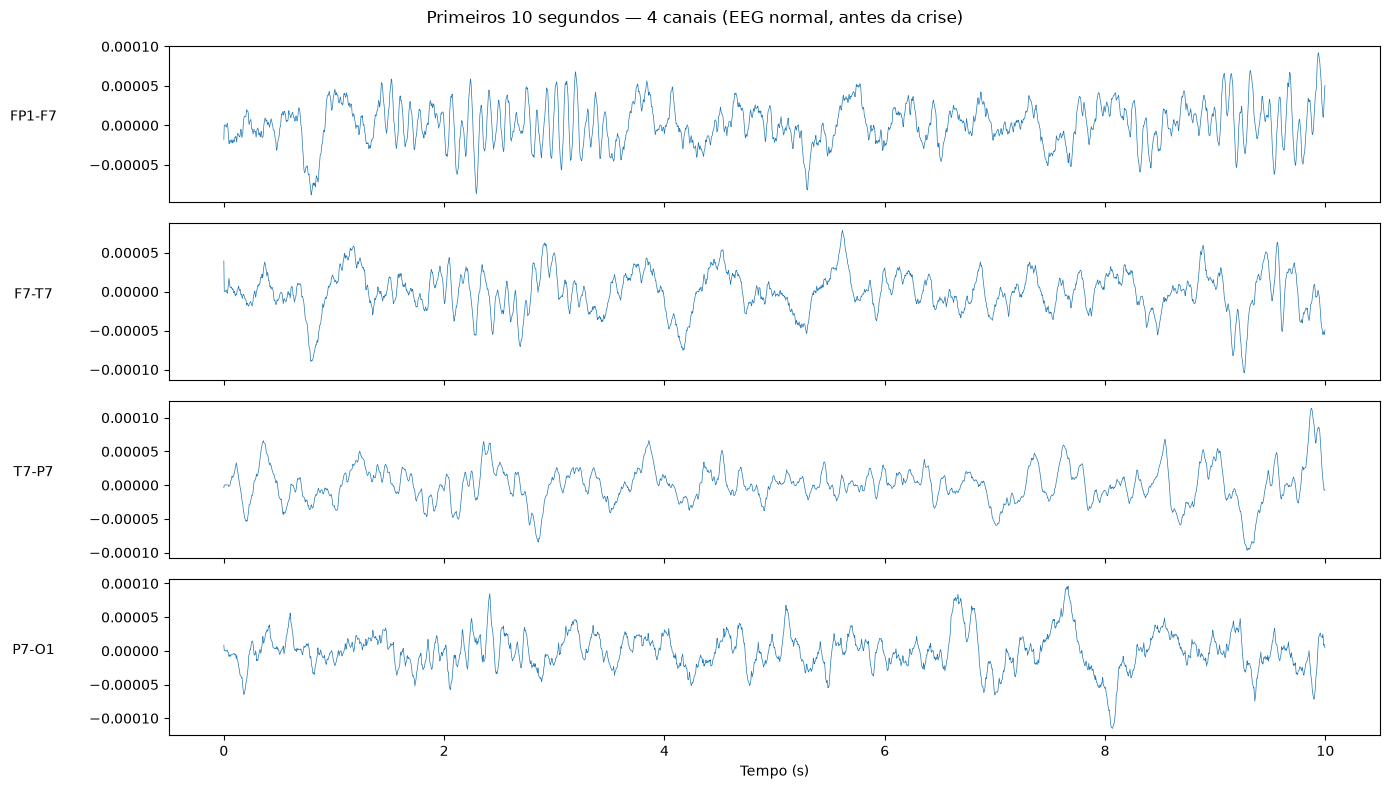

In [6]:
taxa_amostragem = dados_brutos.info['sfreq']

# Vamos pegar os primeiros 10 segundos, dos primeiros 4 canais
duracao_visualizar = 10  # segundos
amostras_visualizar = int(duracao_visualizar * taxa_amostragem)

t = np.arange(amostras_visualizar) / taxa_amostragem

fig, eixos = plt.subplots(4, 1, figsize=(14, 8), sharex=True)

for i in range(4):
    eixos[i].plot(t, dados_array[i, :amostras_visualizar], linewidth=0.5)
    eixos[i].set_ylabel(dados_brutos.ch_names[i], rotation=0, labelpad=40)

eixos[-1].set_xlabel("Tempo (s)")
plt.suptitle("Primeiros 10 segundos — 4 canais (EEG normal, antes da crise)")
plt.tight_layout()
plt.show()

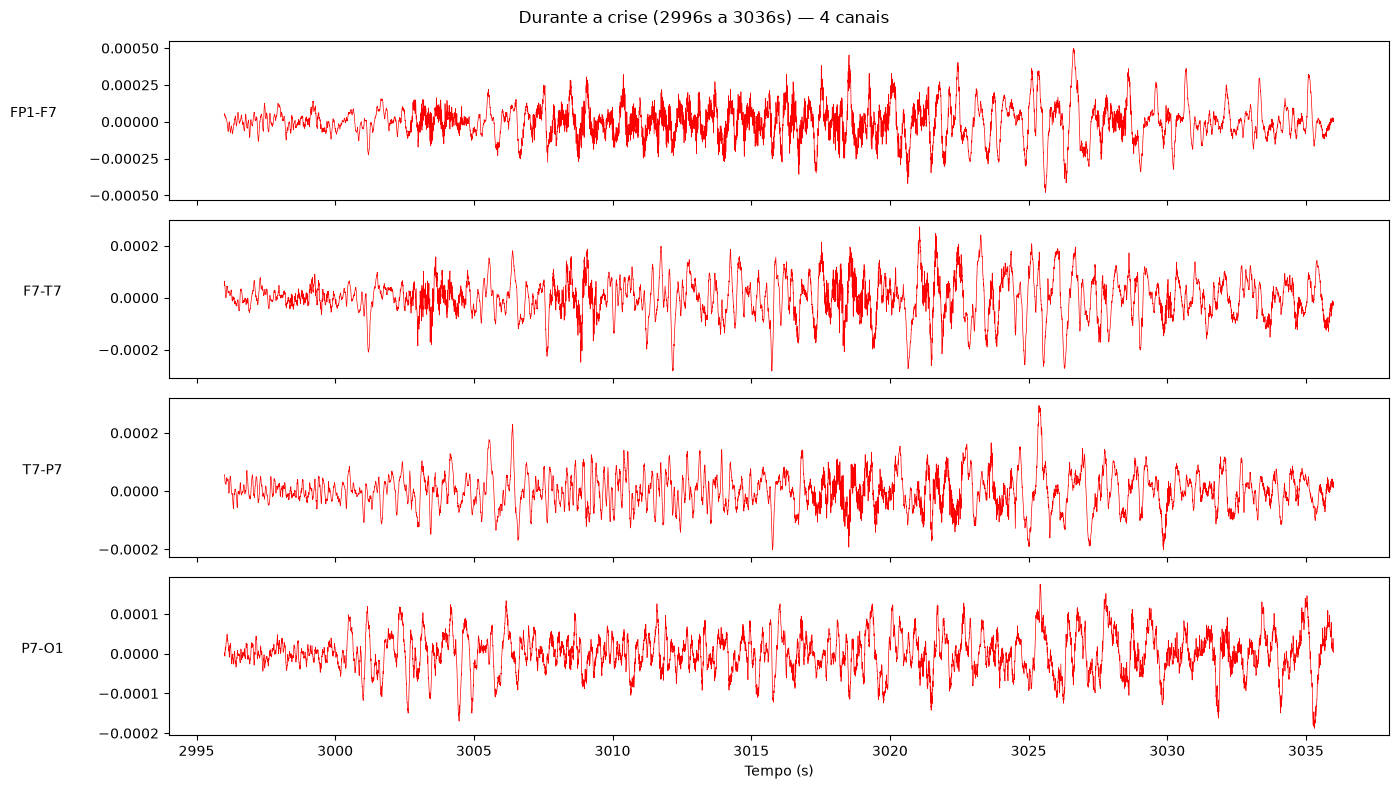

In [7]:
inicio_crise = 2996  # segundos, do summary
fim_crise = 3036

amostra_inicio = int(inicio_crise * taxa_amostragem)
amostra_fim = int(fim_crise * taxa_amostragem)

t_crise = np.arange(amostra_inicio, amostra_fim) / taxa_amostragem

fig, eixos = plt.subplots(4, 1, figsize=(14, 8), sharex=True)

for i in range(4):
    eixos[i].plot(t_crise, dados_array[i, amostra_inicio:amostra_fim], linewidth=0.5, color='red')
    eixos[i].set_ylabel(dados_brutos.ch_names[i], rotation=0, labelpad=40)

eixos[-1].set_xlabel("Tempo (s)")
plt.suptitle(f"Durante a crise ({inicio_crise}s a {fim_crise}s) — 4 canais")
plt.tight_layout()
plt.show()

In [8]:
def parsear_summary(caminho_summary):
    """
    Lê um arquivo -summary.txt do CHB-MIT e extrai, para cada arquivo .edf mencionado,
    se ele contém crises e os horários de início/fim de cada uma.
    
    Retorna uma lista de dicionários, um por arquivo .edf.
    """
    with open(caminho_summary, 'r') as f:
        linhas = f.readlines()
    
    arquivos_info = []
    arquivo_atual = None
    
    for linha in linhas:
        linha = linha.strip()
        
        if linha.startswith("File Name:"):
            # Encontrou um novo arquivo .edf — finaliza o anterior (se existir) e começa um novo
            if arquivo_atual is not None:
                arquivos_info.append(arquivo_atual)
            
            nome_arquivo = linha.replace("File Name:", "").strip()
            arquivo_atual = {
                "arquivo": nome_arquivo,
                "num_crises": 0,
                "crises": []
            }
        
        elif linha.startswith("Number of Seizures in File:"):
            num = int(linha.replace("Number of Seizures in File:", "").strip())
            arquivo_atual["num_crises"] = num
        
        elif "Seizure" in linha and "Start Time:" in linha:
            # Pode ser "Seizure Start Time:" ou "Seizure 1 Start Time:" dependendo do paciente
            valor = linha.split(":")[-1].strip()
            segundos = int(valor.replace("seconds", "").strip())
            # Guarda temporariamente o início; o fim vem na próxima linha relevante
            arquivo_atual.setdefault("_inicio_temp", []).append(segundos)
        
        elif "Seizure" in linha and "End Time:" in linha:
            valor = linha.split(":")[-1].strip()
            segundos = int(valor.replace("seconds", "").strip())
            inicio = arquivo_atual["_inicio_temp"].pop(0)
            arquivo_atual["crises"].append((inicio, segundos))
    
    # Não esquece do último arquivo do arquivo (não tem "File Name:" seguinte para finalizar)
    if arquivo_atual is not None:
        arquivo_atual.pop("_inicio_temp", None)  # remove campo temporário
        arquivos_info.append(arquivo_atual)
    
    return arquivos_info


# Testa com o chb01
info_chb01 = parsear_summary("chb01/chb01-summary.txt")

print(f"Total de arquivos no summary: {len(info_chb01)}")
print(f"\nArquivos com crise:")
for info in info_chb01:
    if info["num_crises"] > 0:
        print(f"  {info['arquivo']}: {info['num_crises']} crise(s) — {info['crises']}")

Total de arquivos no summary: 42

Arquivos com crise:
  chb01_03.edf: 1 crise(s) — [(2996, 3036)]
  chb01_04.edf: 1 crise(s) — [(1467, 1494)]
  chb01_15.edf: 1 crise(s) — [(1732, 1772)]
  chb01_16.edf: 1 crise(s) — [(1015, 1066)]
  chb01_18.edf: 1 crise(s) — [(1720, 1810)]
  chb01_21.edf: 1 crise(s) — [(327, 420)]
  chb01_26.edf: 1 crise(s) — [(1862, 1963)]


In [9]:
def listar_pacientes_disponiveis(caminho_base="."):
    """
    Procura por pastas chbXX dentro do caminho base que contenham
    um arquivo -summary.txt, e retorna a lista de pacientes encontrados.
    """
    pacientes = []
    
    for item in sorted(os.listdir(caminho_base)):
        caminho_pasta = os.path.join(caminho_base, item)
        
        if os.path.isdir(caminho_pasta) and item.startswith("chb"):
            caminho_summary = os.path.join(caminho_pasta, f"{item}-summary.txt")
            
            if os.path.exists(caminho_summary):
                pacientes.append(item)
    
    return pacientes


pacientes_disponiveis = listar_pacientes_disponiveis(".")
print(f"Pacientes encontrados: {pacientes_disponiveis}")

Pacientes encontrados: ['chb01', 'chb02', 'chb03', 'chb04', 'chb05', 'chb06', 'chb07', 'chb08']


In [10]:
def parsear_todos_pacientes(caminho_base, pacientes):
    """
    Aplica parsear_summary() em cada paciente da lista,
    retornando um dicionário {nome_paciente: lista_de_arquivos_info}.
    """
    todos_dados = {}
    
    for paciente in pacientes:
        caminho_summary = os.path.join(caminho_base, paciente, f"{paciente}-summary.txt")
        info_arquivos = parsear_summary(caminho_summary)
        todos_dados[paciente] = info_arquivos
        
        total_crises = sum(info["num_crises"] for info in info_arquivos)
        print(f"{paciente}: {len(info_arquivos)} arquivos, {total_crises} crises no total")
    
    return todos_dados


dados_todos_pacientes = parsear_todos_pacientes(".", pacientes_disponiveis)

chb01: 42 arquivos, 7 crises no total
chb02: 36 arquivos, 3 crises no total
chb03: 38 arquivos, 7 crises no total
chb04: 42 arquivos, 4 crises no total
chb05: 39 arquivos, 5 crises no total
chb06: 18 arquivos, 10 crises no total
chb07: 19 arquivos, 3 crises no total
chb08: 20 arquivos, 5 crises no total


In [ ]:
def extrair_janelas_arquivo(caminho_edf, crises, duracao_janela=2.0, 
                              limite_normais=50, margem_seguranca=10):
    dados_brutos = mne.io.read_raw_edf(caminho_edf, preload=True, verbose=False)

    # ponytail: assume que canal 0 = 'FP1-F7' identifica a montagem padrão
    # e que qualquer canal extra (ECG/VNS/EKG) vem depois do 23º.
    # Se algum paciente novo quebrar essa suposição, trocar por seleção por nome.
    if dados_brutos.ch_names[0] != 'FP1-F7' or len(dados_brutos.ch_names) < 23:
        raise ValueError(f"Montagem incompatível em {caminho_edf}: "
                          f"{len(dados_brutos.ch_names)} canais, 1º={dados_brutos.ch_names[0]}")

 
    dados_array = dados_brutos.get_data()[:23, :]  # descarta canais extras no fim
    taxa = dados_brutos.info['sfreq']
    
    pontos_janela = int(duracao_janela * taxa)
    n_amostras_total = dados_array.shape[1]
    duracao_total = n_amostras_total / taxa
    
    janelas_extraidas = []
    
    # --- ETAPA 1: extrair TODAS as janelas de crise ---
    for inicio_crise, fim_crise in crises:
        amostra_inicio = int(inicio_crise * taxa)
        amostra_fim = int(fim_crise * taxa)
        
        pos = amostra_inicio
        while pos + pontos_janela <= amostra_fim:
            janela = dados_array[:, pos:pos + pontos_janela]
            janelas_extraidas.append((janela, 1))  # rótulo 1 = crise
            pos += pontos_janela
    
    # --- ETAPA 2: extrair janelas NORMAIS, longe das crises ---
    intervalos_proibidos = [(max(0, ini - margem_seguranca), fim + margem_seguranca) 
                             for ini, fim in crises]
    
    def esta_em_intervalo_proibido(tempo_seg):
        for ini, fim in intervalos_proibidos:
            if ini <= tempo_seg <= fim:
                return True
        return False
    
    posicoes_candidatas = np.arange(0, duracao_total - duracao_janela, duracao_janela)
    np.random.shuffle(posicoes_candidatas)
    
    contador_normais = 0
    for tempo_inicio in posicoes_candidatas:
        if contador_normais >= limite_normais:
            break
        
        tempo_fim = tempo_inicio + duracao_janela
        
        if not esta_em_intervalo_proibido(tempo_inicio) and not esta_em_intervalo_proibido(tempo_fim):
            amostra_inicio = int(tempo_inicio * taxa)
            janela = dados_array[:, amostra_inicio:amostra_inicio + pontos_janela]
            
            if janela.shape[1] == pontos_janela:
                janelas_extraidas.append((janela, 0))  # rótulo 0 = normal
                contador_normais += 1
    
    return janelas_extraidas

print("Função de extração definida!")

Função de extração definida!


In [12]:
janelas_teste = extrair_janelas_arquivo(
    "chb01/chb01_03.edf", 
    crises=[(2996, 3036)],
    duracao_janela=2.0,
    limite_normais=50
)

rotulos_teste = [r for _, r in janelas_teste]
print(f"Total de janelas extraídas: {len(janelas_teste)}")
print(f"  Crise (1): {rotulos_teste.count(1)}")
print(f"  Normal (0): {rotulos_teste.count(0)}")
print(f"\nFormato de uma janela: {janelas_teste[0][0].shape}")

Total de janelas extraídas: 70
  Crise (1): 20
  Normal (0): 50

Formato de uma janela: (23, 512)


In [13]:
def construir_dataset_completo(caminho_base, dados_todos_pacientes, 
                                  duracao_janela=2.0, limite_normais=50, 
                                  margem_seguranca=10):
    """
    Percorre todos os pacientes e arquivos disponíveis, extraindo janelas
    rotuladas de cada arquivo .edf que realmente existe em disco.
    
    Retorna: todas_janelas (lista de arrays), todos_rotulos (lista de int),
             info_origem (lista de dicts com paciente/arquivo, para rastreabilidade)
    """
    todas_janelas = []
    todos_rotulos = []
    info_origem = []
    
    for paciente, arquivos_info in dados_todos_pacientes.items():
        pasta_paciente = os.path.join(caminho_base, paciente)
        
        arquivos_processados = 0
        crises_encontradas = 0
        
        for info in arquivos_info:
            caminho_edf = os.path.join(pasta_paciente, info["arquivo"])
            
            # Só processa se o arquivo realmente existir em disco
            if not os.path.exists(caminho_edf):
                continue
            
            try:
                janelas = extrair_janelas_arquivo(
                    caminho_edf, 
                    crises=info["crises"],
                    duracao_janela=duracao_janela,
                    limite_normais=limite_normais,
                    margem_seguranca=margem_seguranca
                )
                
                for janela, rotulo in janelas:
                    todas_janelas.append(janela)
                    todos_rotulos.append(rotulo)
                    info_origem.append({"paciente": paciente, "arquivo": info["arquivo"]})
                
                arquivos_processados += 1
                crises_encontradas += info["num_crises"]
                
            except Exception as e:
                print(f"  ERRO ao processar {caminho_edf}: {e}")
        
        print(f"{paciente}: {arquivos_processados} arquivos processados, "
              f"{crises_encontradas} crises")
    
    todas_janelas = np.array(todas_janelas, dtype=np.float32)
    todos_rotulos = np.array(todos_rotulos, dtype=np.int64)
    
    return todas_janelas, todos_rotulos, info_origem


print("Iniciando extração completa — isso pode levar alguns minutos...\n")

janelas_completas, rotulos_completos, origem_completa = construir_dataset_completo(
    ".", dados_todos_pacientes, 
    duracao_janela=2.0, 
    limite_normais=50, 
    margem_seguranca=10
)

print(f"\n=== RESUMO FINAL ===")
print(f"Total de janelas: {len(janelas_completas)}")
print(f"Formato de cada janela: {janelas_completas[0].shape}")
print(f"Classe 0 (normal): {(rotulos_completos == 0).sum()}")
print(f"Classe 1 (crise):  {(rotulos_completos == 1).sum()}")

Iniciando extração completa — isso pode levar alguns minutos...



chb01: 10 arquivos processados, 7 crises


chb02: 5 arquivos processados, 3 crises


chb03: 9 arquivos processados, 7 crises
chb04: 1 arquivos processados, 0 crises


chb05: 7 arquivos processados, 5 crises


chb06: 9 arquivos processados, 10 crises


chb07: 5 arquivos processados, 3 crises


chb08: 7 arquivos processados, 5 crises

=== RESUMO FINAL ===
Total de janelas: 4127
Formato de cada janela: (23, 512)
Classe 0 (normal): 2650
Classe 1 (crise):  1477


In [14]:
import collections

contagem_por_paciente = collections.Counter([o["paciente"] for o in origem_completa])
print("Janelas por paciente:")
for paciente, count in sorted(contagem_por_paciente.items()):
    print(f"  {paciente}: {count} janelas")

# Separando também por classe
print("\nDetalhamento por paciente e classe:")
for paciente in sorted(contagem_por_paciente.keys()):
    indices_paciente = [i for i, o in enumerate(origem_completa) if o["paciente"] == paciente]
    rotulos_paciente = rotulos_completos[indices_paciente]
    n_normal = (rotulos_paciente == 0).sum()
    n_crise = (rotulos_paciente == 1).sum()
    print(f"  {paciente}: {n_normal} normais, {n_crise} crises")

Janelas por paciente:
  chb01: 719 janelas
  chb02: 335 janelas
  chb03: 649 janelas
  chb04: 50 janelas
  chb05: 628 janelas
  chb06: 525 janelas
  chb07: 412 janelas
  chb08: 809 janelas

Detalhamento por paciente e classe:
  chb01: 500 normais, 219 crises
  chb02: 250 normais, 85 crises
  chb03: 450 normais, 199 crises
  chb04: 50 normais, 0 crises
  chb05: 350 normais, 278 crises
  chb06: 450 normais, 75 crises
  chb07: 250 normais, 162 crises
  chb08: 350 normais, 459 crises


In [15]:
# ==========================================
# ÚNICA LINHA QUE PRECISA MUDAR NO FUTURO
# ==========================================
pacientes_teste = ["chb08"]
# ==========================================

# Todo o resto do código deriva disso automaticamente:
pacientes_treino = [p for p in pacientes_disponiveis if p not in pacientes_teste]

print(f"Pacientes de treino: {pacientes_treino}")
print(f"Pacientes de teste:  {pacientes_teste}")

Pacientes de treino: ['chb01', 'chb02', 'chb03', 'chb04', 'chb05', 'chb06', 'chb07']
Pacientes de teste:  ['chb08']


In [16]:
indices_treino = [i for i, o in enumerate(origem_completa) if o["paciente"] in pacientes_treino]
indices_teste = [i for i, o in enumerate(origem_completa) if o["paciente"] in pacientes_teste]

janelas_treino = janelas_completas[indices_treino]
rotulos_treino = rotulos_completos[indices_treino]
janelas_teste = janelas_completas[indices_teste]
rotulos_teste = rotulos_completos[indices_teste]

print(f"Treino: {len(janelas_treino)} janelas")
print(f"  Normal: {(rotulos_treino == 0).sum()}, Crise: {(rotulos_treino == 1).sum()}")
print(f"\nTeste: {len(janelas_teste)} janelas")
print(f"  Normal: {(rotulos_teste == 0).sum()}, Crise: {(rotulos_teste == 1).sum()}")

Treino: 3318 janelas
  Normal: 2300, Crise: 1018

Teste: 809 janelas
  Normal: 350, Crise: 459


In [17]:
media_treino = janelas_treino.mean()
desvio_treino = janelas_treino.std()

janelas_treino_norm = (janelas_treino - media_treino) / desvio_treino
janelas_teste_norm = (janelas_teste - media_treino) / desvio_treino

print(f"Média do treino: {media_treino:.8f}")
print(f"Desvio padrão do treino: {desvio_treino:.8f}")
print(f"\nApós normalização:")
print(f"  Treino — média: {janelas_treino_norm.mean():.4f}, desvio: {janelas_treino_norm.std():.4f}")
print(f"  Teste  — média: {janelas_teste_norm.mean():.4f}, desvio: {janelas_teste_norm.std():.4f}")

Média do treino: 0.00000022
Desvio padrão do treino: 0.00010593

Após normalização:
  Treino — média: -0.0000, desvio: 1.0000
  Teste  — média: -0.0013, desvio: 1.0587


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

print("PyTorch importado:", torch.__version__)

X_treino = torch.FloatTensor(janelas_treino_norm)
y_treino = torch.LongTensor(rotulos_treino)
X_teste = torch.FloatTensor(janelas_teste_norm)
y_teste = torch.LongTensor(rotulos_teste)

print(f"X_treino: {X_treino.shape}  (batch, canais, pontos)")
print(f"X_teste:  {X_teste.shape}")

PyTorch importado: 2.13.0+cpu
X_treino: torch.Size([3318, 23, 512])  (batch, canais, pontos)
X_teste:  torch.Size([809, 23, 512])


In [19]:
from torch.utils.data import DataLoader, TensorDataset

dataset_treino = TensorDataset(X_treino, y_treino)
dataset_teste = TensorDataset(X_teste, y_teste)

loader_treino = DataLoader(dataset_treino, batch_size=32, shuffle=True)
loader_teste = DataLoader(dataset_teste, batch_size=32, shuffle=False)

print(f"Batches de treino: {len(loader_treino)}")
print(f"Batches de teste: {len(loader_teste)}")

Batches de treino: 104
Batches de teste: 26


In [20]:
class CNN1D_EEG_Multicanal(nn.Module):
    def __init__(self, num_classes=2, pontos_por_janela=512):
        super().__init__()
        
        # Camada 1: agora recebe 23 canais simultaneamente
        self.conv1 = nn.Conv1d(in_channels=23, out_channels=16, kernel_size=21, padding=10)
        self.conv2 = nn.Conv1d(in_channels=16, out_channels=32, kernel_size=11, padding=5)
        self.conv3 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=7, padding=3)
        self.pool = nn.MaxPool1d(kernel_size=2)
        
        with torch.no_grad():
            ficticio = torch.zeros(1, 23, pontos_por_janela)
            ficticio = self.pool(self.conv1(ficticio))
            ficticio = self.pool(self.conv2(ficticio))
            ficticio = self.pool(self.conv3(ficticio))
            tamanho_achatado = ficticio.view(1, -1).shape[1]
        
        print(f"Tamanho após achatamento: {tamanho_achatado}")
        
        self.fc1 = nn.Linear(tamanho_achatado, 64)
        self.fc2 = nn.Linear(64, num_classes)
        
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.2)
    
    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

modelo = CNN1D_EEG_Multicanal(num_classes=2, pontos_por_janela=512)
print(modelo)
total_params = sum(p.numel() for p in modelo.parameters())
print(f"\nTotal de parâmetros: {total_params:,}")

Tamanho após achatamento: 4096
CNN1D_EEG_Multicanal(
  (conv1): Conv1d(23, 16, kernel_size=(21,), stride=(1,), padding=(10,))
  (conv2): Conv1d(16, 32, kernel_size=(11,), stride=(1,), padding=(5,))
  (conv3): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
)

Total de parâmetros: 290,146


In [21]:
criterio = nn.CrossEntropyLoss()
otimizador = optim.Adam(modelo.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(otimizador, step_size=8, gamma=0.5)

print("Critério, otimizador e scheduler prontos!")

Critério, otimizador e scheduler prontos!


In [22]:
num_epocas = 50

for epoca in range(num_epocas):
    modelo.train()
    perda_acumulada = 0.0
    acertos = 0
    total = 0
    
    for entradas, rotulos_batch in loader_treino:
        otimizador.zero_grad()
        saidas = modelo(entradas)
        perda = criterio(saidas, rotulos_batch)
        perda.backward()
        otimizador.step()
        
        perda_acumulada += perda.item()
        _, previstos = saidas.max(1)
        acertos += (previstos == rotulos_batch).sum().item()
        total += rotulos_batch.size(0)
    
    scheduler.step()
    lr_atual = otimizador.param_groups[0]['lr']
    perda_media = perda_acumulada / len(loader_treino)
    acuracia = 100 * acertos / total
    print(f"Época {epoca+1}/{num_epocas} — Perda: {perda_media:.4f} — Acurácia: {acuracia:.2f}% — LR: {lr_atual:.6f}")

print("\nTreinamento concluído!")

Época 1/50 — Perda: 0.2842 — Acurácia: 88.88% — LR: 0.001000
Época 2/50 — Perda: 0.1330 — Acurácia: 95.60% — LR: 0.001000
Época 3/50 — Perda: 0.1028 — Acurácia: 96.50% — LR: 0.001000
Época 4/50 — Perda: 0.0771 — Acurácia: 97.35% — LR: 0.001000
Época 5/50 — Perda: 0.0591 — Acurácia: 98.01% — LR: 0.001000
Época 6/50 — Perda: 0.0598 — Acurácia: 97.86% — LR: 0.001000
Época 7/50 — Perda: 0.0514 — Acurácia: 98.31% — LR: 0.001000
Época 8/50 — Perda: 0.0363 — Acurácia: 98.49% — LR: 0.000500
Época 9/50 — Perda: 0.0169 — Acurácia: 99.52% — LR: 0.000500
Época 10/50 — Perda: 0.0175 — Acurácia: 99.46% — LR: 0.000500
Época 11/50 — Perda: 0.0119 — Acurácia: 99.70% — LR: 0.000500
Época 12/50 — Perda: 0.0042 — Acurácia: 99.91% — LR: 0.000500
Época 13/50 — Perda: 0.0026 — Acurácia: 99.97% — LR: 0.000500
Época 14/50 — Perda: 0.0140 — Acurácia: 99.49% — LR: 0.000500
Época 15/50 — Perda: 0.0129 — Acurácia: 99.67% — LR: 0.000500
Época 16/50 — Perda: 0.0067 — Acurácia: 99.73% — LR: 0.000250
Época 17/50 — Per

In [23]:
modelo.eval()
acertos = 0
total = 0

with torch.no_grad():
    for entradas, rotulos_batch in loader_teste:
        saidas = modelo(entradas)
        _, previstos = saidas.max(1)
        acertos += (previstos == rotulos_batch).sum().item()
        total += rotulos_batch.size(0)

acuracia_teste = 100 * acertos / total
print(f"Acurácia no teste (paciente NUNCA visto: chb08): {acuracia_teste:.2f}%")
print(f"Acertos: {acertos}/{total}")

Acurácia no teste (paciente NUNCA visto: chb08): 61.68%
Acertos: 499/809


In [24]:
from sklearn.metrics import confusion_matrix, classification_report

modelo.eval()
todas_previsoes = []
todos_rotulos = []

with torch.no_grad():
    for entradas, rotulos_batch in loader_teste:
        saidas = modelo(entradas)
        _, previstos = saidas.max(1)
        todas_previsoes.extend(previstos.numpy())
        todos_rotulos.extend(rotulos_batch.numpy())

nomes_classes = ["Normal", "Crise"]
cm = confusion_matrix(todos_rotulos, todas_previsoes)

print("=== MATRIZ DE CONFUSÃO (teste: chb08, nunca visto no treino) ===\n")
print(f"{'':>10} {'Prev Normal':>12} {'Prev Crise':>12}")
for i, nome in enumerate(nomes_classes):
    print(f"{nome:>10} {cm[i][0]:>12} {cm[i][1]:>12}")

print(f"\n=== RELATÓRIO DE CLASSIFICAÇÃO ===\n")
print(classification_report(todos_rotulos, todas_previsoes, target_names=nomes_classes))

=== MATRIZ DE CONFUSÃO (teste: chb08, nunca visto no treino) ===

            Prev Normal   Prev Crise
    Normal          339           11
     Crise          299          160

=== RELATÓRIO DE CLASSIFICAÇÃO ===

              precision    recall  f1-score   support

      Normal       0.53      0.97      0.69       350
       Crise       0.94      0.35      0.51       459

    accuracy                           0.62       809
   macro avg       0.73      0.66      0.60       809
weighted avg       0.76      0.62      0.59       809

